<a href="https://colab.research.google.com/github/MarouaDhm/industrial-predictive-maintenance/blob/main/predictive_maintenance_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv("ai4i2020.csv")
df.head()


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [ ]:
print(df.columns)


Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='object')


In [ ]:
print(df.shape)


(10000, 14)


In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

In [ ]:
df.isnull().sum()

,0
UDI,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Machine failure,0
TWF,0


In [ ]:
df.describe()


,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [ ]:
print(df["Machine failure"].value_counts())
print(df["Machine failure"].value_counts(normalize=True) * 100)

Machine failure
0    9661
1     339
Name: count, dtype: int64
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


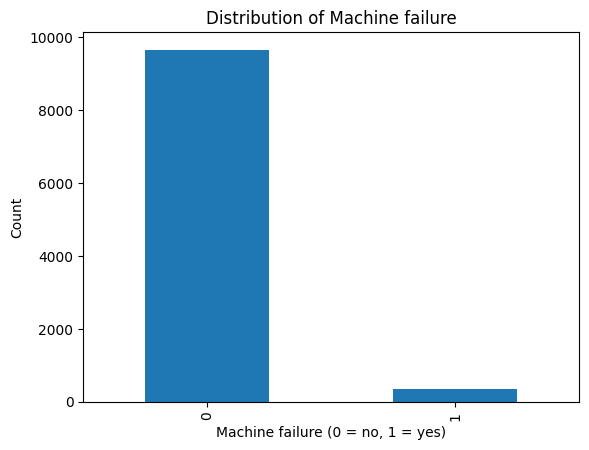

In [ ]:
df["Machine failure"].value_counts().plot(kind="bar")
plt.title("Distribution of Machine failure")
plt.xlabel("Machine failure (0 = no, 1 = yes)")
plt.ylabel("Count")
plt.show()

In [ ]:
df = pd.read_csv("ai4i2020.csv")
df = df.drop(columns=["UDI" ,"Product ID"])


In [ ]:
df.head()

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [ ]:
df.columns = ['type', 'air_temp', 'process_temp', 'rot_speed', 'torque', 'tool_wear', 'failure', 'TWF' , 'HDF', 'PWF', 'OSF', 'RNF']


In [ ]:
df["type"] = df["type"].map({"L": 0, "M": 1, "H": 2})
df["type"].value_counts()

,count
type,
0,6000
1,2997
2,1003


In [ ]:
y = df["failure"]
X = df.drop(columns=["failure", "TWF", "HDF", "PWF", "OSF", "RNF"])

In [ ]:
print(X.shape)
print(X.columns)
print(y.value_counts())

(10000, 6)
Index(['type', 'air_temp', 'process_temp', 'rot_speed', 'torque', 'tool_wear'], dtype='object')
failure
0    9661
1     339
Name: count, dtype: int64


In [ ]:
X_fe = X.copy()
X_fe["temp_diff"] = X_fe["process_temp"] - X_fe["air_temp"]
X_fe["power"] = X_fe["torque"] * X_fe["rot_speed"] * (2 * np.pi / 60)
X_fe["wear_torque"] = X_fe["tool_wear"] * X_fe["torque"]
print(X_fe.shape)
X_fe.head()

(10000, 9)


,type,air_temp,process_temp,rot_speed,torque,tool_wear,temp_diff,power,wear_torque
0,1,298.1,308.6,1551,42.8,0,10.5,6951.590560,0.0
1,0,298.2,308.7,1408,46.3,3,10.5,6826.722724,138.9
2,0,298.1,308.5,1498,49.4,5,10.4,7749.387543,247.0
3,0,298.2,308.6,1433,39.5,7,10.4,5927.504659,276.5
4,0,298.2,308.7,1408,40.0,9,10.5,5897.816608,360.0


In [ ]:
from sklearn.model_selection import train_test_split

X_train_fe, X_test_fe, y_train, y_test = train_test_split(
    X_fe, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)


X_train = X_train_fe[X.columns]
X_test = X_test_fe[X.columns]

print(X_train_fe.shape, X_test_fe.shape)
print(y_train.value_counts(normalize=True) * 100)
print(y_test.value_counts(normalize=True) * 100)

(8000, 9) (2000, 9)
failure
0    96.6125
1     3.3875
Name: proportion, dtype: float64
failure
0    96.6
1     3.4
Name: proportion, dtype: float64


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

lr = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(class_weight="balanced", max_iter=1000))
])

lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)

print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[1585  347]
 [  12   56]]
              precision    recall  f1-score   support

           0       0.99      0.82      0.90      1932
           1       0.14      0.82      0.24        68

    accuracy                           0.82      2000
   macro avg       0.57      0.82      0.57      2000
weighted avg       0.96      0.82      0.88      2000



In [ ]:
from sklearn.ensemble import RandomForestClassifier

def evaluate(model, Xtr, Xte, name):
    model.fit(Xtr, y_train)
    pred = model.predict(Xte)
    print("=====", name, "=====")
    print(confusion_matrix(y_test, pred))
    print(classification_report(y_test, pred))

rf = RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42)
evaluate(rf, X_train, X_test, "RF - 6 features")

rf_fe = RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42)
evaluate(rf_fe, X_train_fe, X_test_fe, "RF - 9 features")

===== RF - 6 features =====
[[1928    4]
 [  31   37]]
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1932
           1       0.90      0.54      0.68        68

    accuracy                           0.98      2000
   macro avg       0.94      0.77      0.83      2000
weighted avg       0.98      0.98      0.98      2000

===== RF - 9 features =====
[[1930    2]
 [  19   49]]
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      1932
           1       0.96      0.72      0.82        68

    accuracy                           0.99      2000
   macro avg       0.98      0.86      0.91      2000
weighted avg       0.99      0.99      0.99      2000



In [ ]:


from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix


def evaluate(model, Xtr, Xte, name):
    model.fit(Xtr, y_train)
    pred = model.predict(Xte)
    print("=====", name, "=====")
    cm = confusion_matrix(y_test, pred)
    print(cm)
    print(classification_report(y_test, pred))
    tn, fp, fn, tp = cm.ravel()
    print("FDR =", round(fp / (tp + fp), 4))


spw = (y_train == 0).sum() / (y_train == 1).sum()
print("scale_pos_weight =", spw)

xgb = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    scale_pos_weight=spw,
    eval_metric="logloss",
    random_state=42
)

evaluate(xgb, X_train_fe, X_test_fe, "XGBoost - 9 features")

scale_pos_weight = 28.52029520295203
===== XGBoost - 9 features =====
[[1912   20]
 [  11   57]]
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.74      0.84      0.79        68

    accuracy                           0.98      2000
   macro avg       0.87      0.91      0.89      2000
weighted avg       0.99      0.98      0.98      2000

FDR = 0.2597


In [ ]:
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import precision_recall_curve, confusion_matrix, classification_report

rf_final = RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 1) Get unbiased probabilities on the training set:
#    each row is predicted by a model that never saw it during training (5-fold CV)
probs_cv = cross_val_predict(rf_final, X_train_fe, y_train, cv=skf, method="predict_proba")[:, 1]

# 2) Compute precision and recall for every possible threshold
prec, rec, thr = precision_recall_curve(y_train, probs_cv)

# 3) Pick the lowest threshold that reaches precision >= 0.95 (i.e. FDR <= 5%).
#    prec has one more element than thr, so we drop its last value to align them.
#    The lowest valid threshold keeps recall as high as possible.
ok = np.where(prec[:-1] >= 0.95)[0]
if len(ok) == 0:
    print("No threshold reaches the target. Lower the precision target (e.g. 0.90).")
else:
    best_thr = thr[ok[0]]
    print("best threshold =", best_thr)

    # 4) Evaluate on the test set ONCE, using the threshold chosen on train only
    rf_final.fit(X_train_fe, y_train)
    probs_test = rf_final.predict_proba(X_test_fe)[:, 1]

    # Convert probabilities to 0/1 decisions with the new threshold (instead of 0.5)
    pred_thr = (probs_test >= best_thr).astype(int)

    cm = confusion_matrix(y_test, pred_thr)
    print(cm)
    print(classification_report(y_test, pred_thr))

    # FDR = false positives / all predicted failures
    tn, fp, fn, tp = cm.ravel()
    print("FDR =", round(fp / (tp + fp), 4))

best threshold = 0.43
[[1930    2]
 [  13   55]]
              precision    recall  f1-score   support

           0       0.99      1.00      1.00      1932
           1       0.96      0.81      0.88        68

    accuracy                           0.99      2000
   macro avg       0.98      0.90      0.94      2000
weighted avg       0.99      0.99      0.99      2000

FDR = 0.0351


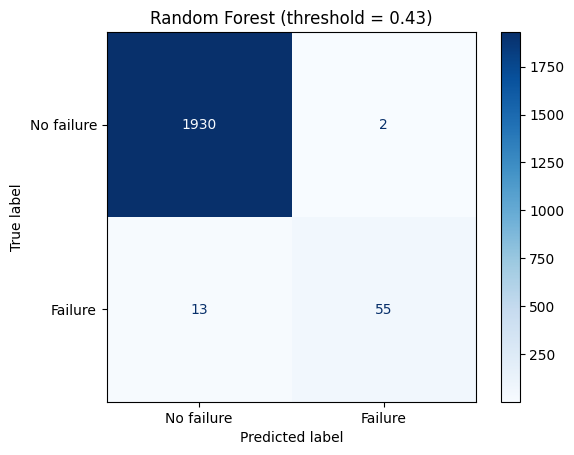

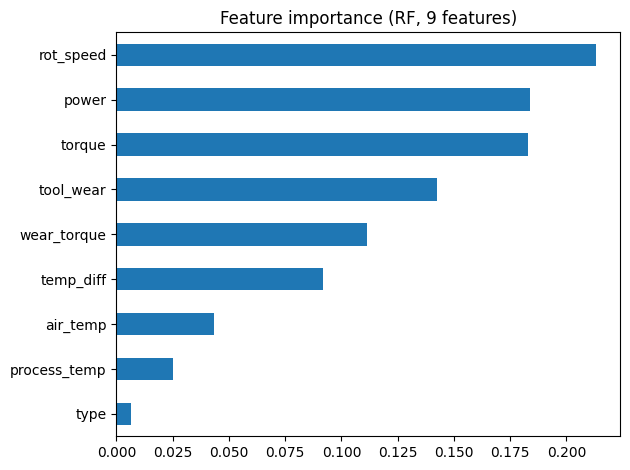

rot_speed       0.213155
power           0.183602
torque          0.182855
tool_wear       0.142359
wear_torque     0.111233
temp_diff       0.091798
air_temp        0.043275
process_temp    0.025179
type            0.006545
dtype: float64


['predictive_maintenance_model.pkl']

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import joblib
from sklearn.metrics import ConfusionMatrixDisplay

# 1) Confusion matrix plot at the chosen threshold
ConfusionMatrixDisplay.from_predictions(
    y_test, pred_thr, display_labels=["No failure", "Failure"], cmap="Blues"
)
plt.title(f"Random Forest (threshold = {best_thr:.2f})")
plt.show()

# 2) Feature importance: do the engineered features matter?
imp = pd.Series(rf_final.feature_importances_, index=X_train_fe.columns).sort_values()
imp.plot(kind="barh", title="Feature importance (RF, 9 features)")
plt.tight_layout()
plt.show()
print(imp.sort_values(ascending=False))

# 3) Save model + threshold together (needed for Task 10)
joblib.dump({"model": rf_final, "threshold": float(best_thr),
             "features": list(X_train_fe.columns)}, "predictive_maintenance_model.pkl")

torque          0.191321
wear_torque     0.190427
power           0.176039
temp_diff      -0.111676
tool_wear       0.105448
air_temp        0.082556
rot_speed      -0.044188
type           -0.036715
process_temp    0.035946
Name: failure, dtype: float64


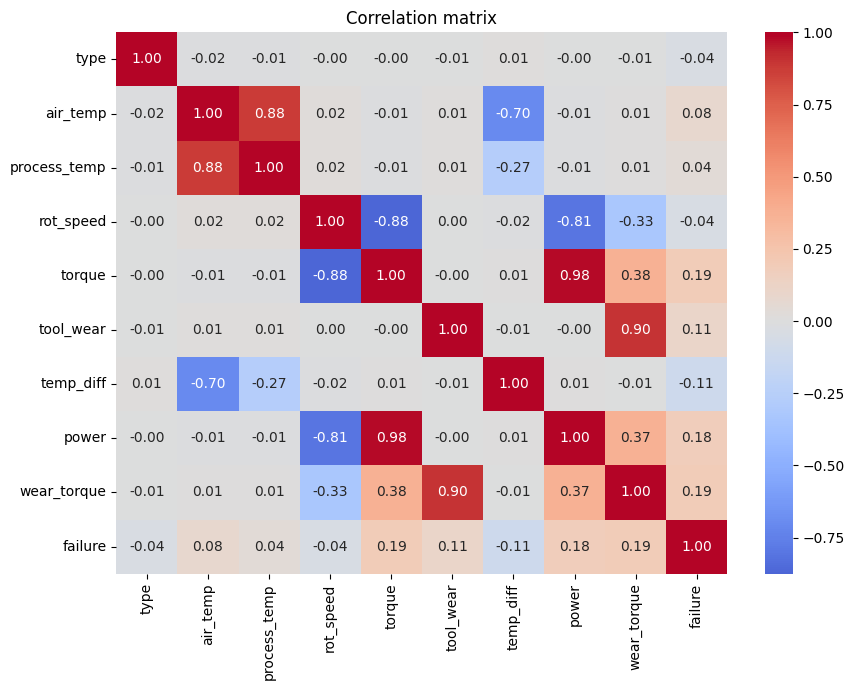

           air_temp  process_temp    rot_speed     torque   tool_wear
failure                                                              
0        299.973999    309.995570  1540.260014  39.629655  106.693717
1        300.886431    310.290265  1496.486726  50.168142  143.781711


In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Rebuild a table with all features + target (same row order as X_fe and y)
tmp = X_fe.copy()
tmp["failure"] = y

# 1) Correlation of each feature with failure (Pearson with a binary target)
corr_target = (tmp.corr()["failure"]
               .drop("failure")
               .sort_values(key=abs, ascending=False))
print(corr_target)

# 2) Heatmap of all pairwise correlations
plt.figure(figsize=(9, 7))
sns.heatmap(tmp.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.tight_layout()
plt.show()

# 3) Mean of each sensor for healthy vs failed machines
print(tmp.groupby("failure")[["air_temp", "process_temp", "rot_speed",
                              "torque", "tool_wear"]].mean())

In [ ]:
from sklearn.model_selection import cross_validate

# 5-fold stratified CV on the full dataset (9 features)
rf_cv = RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42)
scores = cross_validate(
    rf_cv, X_fe, y, cv=skf,
    scoring=["precision", "recall", "f1"]
)

for m in ["precision", "recall", "f1"]:
    s = scores[f"test_{m}"]
    print(f"{m}: {s.mean():.3f} +/- {s.std():.3f}")

precision: 0.972 +/- 0.023
recall: 0.791 +/- 0.030
f1: 0.871 +/- 0.015
